# MOT 2024: analysis

Step 5 and 6 of `docs/instructions.md`. Every query runs on the tables built in `02_load_and_clean.ipynb` and `03_looksups.ipynb`.

**Scope** (data dictionary section 8): Class 4 vehicles (cars and light vans), initial tests only (`test_type = 'NT'`), results P, F or PRS. Make and model questions also drop `UNCLASSIFIED`.

In [1]:
import duckdb
import os
import textwrap
import matplotlib.pyplot as plt

con = duckdb.connect("../data/mot.duckdb")
os.makedirs("../reports/figures", exist_ok=True)

## 1. Define the scope once

A view, not a table, so it always reflects `test_result_clean`. I also add `age`: the vehicle age with impossible first-use years removed. About 30 tests have years such as 94, 211 or 1012, which gave a `vehicle_age_years` of up to 1930. Ages over 60 are mostly real classic cars, so I keep those.

In [2]:
con.execute("""
CREATE OR REPLACE VIEW analysis_scope AS
SELECT *,
       -- a few dozen rows have first-use years like 94 or 1012; treat them as unknown
       CASE WHEN first_use_year >= 1900 THEN vehicle_age_years END AS age
FROM test_result_clean
WHERE test_class_id = '4'
  AND test_type = 'NT'
  AND test_result IN ('P', 'F', 'PRS')
""")

## 2. Sanity check: the overall failure rate

DVSA's published initial failure rate for cars is in the high 20s, and my January bias check gave 30.0%, so I expect a number close to those.

In [3]:
con.sql("""
SELECT COUNT(*)                                          AS tests,
       COUNT(*) FILTER (WHERE test_result IN ('F','PRS')) AS initial_fails,
       ROUND(100 * AVG(is_initial_fail::INT), 1)          AS initial_fail_pct,
       ROUND(100 * AVG((test_result = 'F')::INT), 1)      AS final_fail_pct
FROM analysis_scope
""").show()

┌──────────┬───────────────┬──────────────────┬────────────────┐
│  tests   │ initial_fails │ initial_fail_pct │ final_fail_pct │
│  int64   │     int64     │      double      │     double     │
├──────────┼───────────────┼──────────────────┼────────────────┤
│ 32968239 │       9322473 │             28.3 │           22.8 │
└──────────┴───────────────┴──────────────────┴────────────────┘



**28.3% of 32,968,239 initial car tests failed** (F or PRS), and 22.8% ended as a fail after PRS repairs. That's in line with DVSA's published figures, so the cleaning hasn't distorted the overall picture.

## 3. Failure rate by vehicle age

In [4]:
by_age = con.sql("""
SELECT age,
       COUNT(*)                                  AS tests,
       ROUND(100 * AVG(is_initial_fail::INT), 1) AS fail_pct
FROM analysis_scope
WHERE age BETWEEN 3 AND 30
GROUP BY age
ORDER BY age
""").df()
by_age

,age,tests,fail_pct
0,3,1864655,12.4
1,4,1771294,13.1
2,5,2477634,15.1
3,6,2481377,17.5
4,7,2596787,20.2
5,8,2709876,23.3
6,9,2610640,26.5
7,10,2374697,30.1
8,11,2087963,33.2
9,12,1788864,35.7


The rate climbs steadily from **12.4% at 3 years to about 44% at 16–20 years**, then *falls*, to 32.5% at 30 years. A likely explanation is survivorship: a car that's still on the road at 25 is usually one somebody looks after (enthusiast-owned, low mileage), while the neglected ones have already been scrapped. I can't prove that with this data, but the mileage results below are consistent with it.

## 4. Failure rate by mileage

In [5]:
by_mileage = con.sql("""
SELECT CASE
         WHEN test_mileage <  30000 THEN '1. under 30k'
         WHEN test_mileage <  60000 THEN '2. 30-60k'
         WHEN test_mileage <  90000 THEN '3. 60-90k'
         WHEN test_mileage < 120000 THEN '4. 90-120k'
         WHEN test_mileage < 150000 THEN '5. 120-150k'
         ELSE                            '6. 150k+'
       END                                       AS mileage_band,
       COUNT(*)                                  AS tests,
       ROUND(100 * AVG(is_initial_fail::INT), 1) AS fail_pct
FROM analysis_scope
WHERE test_mileage IS NOT NULL
GROUP BY mileage_band
ORDER BY mileage_band
""").df()
by_mileage

,mileage_band,tests,fail_pct
0,1. under 30k,5060748,11.6
1,2. 30-60k,9542778,21.0
2,3. 60-90k,8035659,31.8
3,4. 90-120k,5302390,39.0
4,5. 120-150k,2816892,41.8
5,6. 150k+,2143826,42.1


The rate more than triples from **11.6% under 30k miles to 39.0% at 90–120k**, then levels off at about 42%. The leveling looks like the age curve: a car that has reached high mileage is one whose owner has kept on maintaining it. *Caveat:* 330,098 tests with missing or implausible mileage are left out (data dictionary 7.7).

## 5. Failure rate by fuel type, at the same age

Electric and hybrid cars are younger on average, so comparing raw rates would flatter them. I compare the four main fuel types within the same age band.

In [6]:
by_fuel = con.sql("""
SELECT fuel_type_desc,
       CASE WHEN age BETWEEN 3 AND 5  THEN '3-5'
            WHEN age BETWEEN 6 AND 9  THEN '6-9'
            WHEN age BETWEEN 10 AND 14 THEN '10-14'
       END                                       AS age_band,
       COUNT(*)                                  AS tests,
       ROUND(100 * AVG(is_initial_fail::INT), 1) AS fail_pct
FROM analysis_scope
WHERE fuel_type IN ('PE', 'DI', 'HY', 'EL')
  AND age BETWEEN 3 AND 14
GROUP BY ALL
ORDER BY fuel_type_desc, MIN(age)
""").df()
by_fuel

,fuel_type_desc,age_band,tests,fail_pct
0,Diesel,3-5,1647539,17.2
1,Diesel,6-9,4772444,23.6
2,Diesel,10-14,4650748,35.8
3,Electric,3-5,341990,13.5
4,Electric,6-9,47794,23.2
5,Electric,10-14,18422,32.5
6,Hybrid,3-5,725038,11.0
7,Hybrid,6-9,388428,16.4
8,Hybrid,10-14,126861,23.7
9,Petrol,3-5,3339870,12.6


**Hybrids have the lowest fail rate in every age band** (11.0% at 3–5 years against 12.6% for petrol and 17.2% for diesel), and **diesel has the highest in every band**. Electric cars sit between petrol and diesel at 3–5 years. *Caveat:* only 18,422 electric tests are 10–14 years old, so that bar is based on a small, early-adopter fleet.

## 6. Which systems fail?

Following data dictionary section 8, a test counts once per category if it has one or more F or P items in that category. I build that per-test list once, because sections 6–9 all reuse it.

In [7]:
con.execute("""
CREATE OR REPLACE TABLE scope_test_category AS
SELECT DISTINCT i.test_id, i.section_name
FROM test_item_labelled i
JOIN analysis_scope s ON i.test_id = s.test_id
WHERE i.rfr_type_code IN ('F', 'P')
  AND i.section_name IS NOT NULL
""")
con.sql("SELECT COUNT(*) AS test_category_rows FROM scope_test_category").show()

┌────────────────────┐
│ test_category_rows │
│       int64        │
├────────────────────┤
│           15781009 │
└────────────────────┘



In [8]:
con.sql("""
SELECT c.section_name,
       COUNT(*)                                                         AS failed_tests,
       ROUND(100 * COUNT(*) / (SELECT COUNT(*) FROM analysis_scope), 1) AS pct_of_all_tests
FROM scope_test_category c
GROUP BY c.section_name
ORDER BY failed_tests DESC
""").show(max_width=200)

┌────────────────────────────────────────────────┬──────────────┬──────────────────┐
│                  section_name                  │ failed_tests │ pct_of_all_tests │
│                    varchar                     │    int64     │      double      │
├────────────────────────────────────────────────┼──────────────┼──────────────────┤
│ Lamps, reflectors and electrical equipment     │      3622537 │             11.0 │
│ Suspension                                     │      2891779 │              8.8 │
│ Brakes                                         │      2226803 │              6.8 │
│ Tyres                                          │      2120892 │              6.4 │
│ Visibility                                     │      1526757 │              4.6 │
│ Body, chassis, structure                       │      1131534 │              3.4 │
│ Noise, emissions and leaks                     │      1042721 │              3.2 │
│ Steering                                       │       650905 │

**Lighting and electrical** defects hit 11.0% of all tests, followed by **suspension** (8.8%), **brakes** (6.8%) and **tyres** (6.4%). A failed test can have defects in several categories, so these percentages add up to more than the 28.3% fail rate.

## 7. How the failing systems change with age (JOIN + CTE)

In [9]:
cat_age = con.sql("""
WITH tests_per_age AS (
    SELECT age, COUNT(*) AS tests
    FROM analysis_scope
    WHERE age BETWEEN 3 AND 25
    GROUP BY age
)
SELECT s.age,
       c.section_name,
       ROUND(100 * COUNT(*) / ANY_VALUE(t.tests), 2) AS pct_of_tests
FROM scope_test_category c
JOIN analysis_scope s  ON c.test_id = s.test_id
JOIN tests_per_age t   ON s.age = t.age
GROUP BY s.age, c.section_name
ORDER BY s.age, pct_of_tests DESC
""").df()
cat_age

,age,section_name,pct_of_tests
0,3,Tyres,5.15
1,3,Visibility,2.98
2,3,"Lamps, reflectors and electrical equipment",2.91
3,3,Brakes,1.69
4,3,Suspension,0.63
...,...,...,...
317,25,Identification of the vehicle,0.77
318,25,Road Wheels,0.31
319,25,Speedometer and speed limiter,0.04
320,25,Seat belt installation check,0.01


In [10]:
top5 = ["Lamps, reflectors and electrical equipment", "Suspension", "Brakes", "Tyres", "Visibility"]
cat_age_wide = cat_age.pivot(index="age", columns="section_name", values="pct_of_tests")[top5]
cat_age_wide.loc[[3, 5, 8, 10, 12, 15, 18, 20, 25]]

section_name,"Lamps, reflectors and electrical equipment",Suspension,Brakes,Tyres,Visibility
age,,,,,
3,2.91,0.63,1.69,5.15,2.98
5,3.74,1.38,2.85,5.20,3.22
8,6.78,5.91,4.76,6.46,3.51
10,10.88,9.19,6.66,7.08,4.39
12,15.16,12.98,8.29,7.18,5.04
15,19.34,16.73,10.59,7.65,6.54
18,21.77,17.33,13.28,7.35,7.32
20,21.58,17.00,13.92,6.56,7.73
25,16.33,12.97,12.15,4.10,6.78


This is the engineering story. On a 3-year-old car, **tyres are the top cause of failure** (5.2% of tests): they're a wear item that depends on the driver, not the car's age, so they stay flat at 5–8% throughout. The **age-driven systems** start near zero and overtake tyres by about 8 years. Suspension goes from 0.6% to 17.3% (a 27-fold rise), driven by corroding springs, worn bushes and ball joints, and lighting goes from 2.9% to 21.8%. Brakes rise steadily too (1.7% to 13.9%), as discs and pipes corrode.

## 8. Top 3 failing systems per make (window function)

Again limited to cars aged 8–12 years, so each make is compared at the same age.

In [11]:
top_per_make = con.sql("""
WITH make_tests AS (
    SELECT make, COUNT(*) AS tests
    FROM analysis_scope
    WHERE NOT is_unclassified AND age BETWEEN 8 AND 12
    GROUP BY make
    HAVING COUNT(*) >= 100000
),
make_category AS (
    SELECT s.make, c.section_name, COUNT(*) AS failed_tests
    FROM scope_test_category c
    JOIN analysis_scope s ON c.test_id = s.test_id
    WHERE s.age BETWEEN 8 AND 12
      AND s.make IN (SELECT make FROM make_tests)
    GROUP BY s.make, c.section_name
),
ranked AS (
    SELECT mc.make,
           mc.section_name,
           ROUND(100 * mc.failed_tests / mt.tests, 1)                       AS pct_of_tests,
           RANK() OVER (PARTITION BY mc.make ORDER BY mc.failed_tests DESC) AS rnk
    FROM make_category mc
    JOIN make_tests mt USING (make)
)
SELECT * FROM ranked WHERE rnk <= 3 ORDER BY make, rnk
""").df()
top_per_make

,make,section_name,pct_of_tests,rnk
0,AUDI,Tyres,7.3,1
1,AUDI,Suspension,6.9,2
2,AUDI,"Lamps, reflectors and electrical equipment",5.6,3
3,BMW,"Lamps, reflectors and electrical equipment",7.7,1
4,BMW,Tyres,7.4,2
...,...,...,...,...
61,VOLKSWAGEN,"Lamps, reflectors and electrical equipment",7.6,2
62,VOLKSWAGEN,Tyres,6.6,3
63,VOLVO,"Lamps, reflectors and electrical equipment",7.8,1
64,VOLVO,Suspension,7.6,2


Lighting or suspension is the top category for almost every make. The exceptions are informative: **Audi's top failure is tyres** and **Kia's is brakes**. Renault, Fiat, Nissan and Mazda are led by suspension, at 11–18% of tests.

## 9. Electric cars fail differently (fuel × category)

Cars aged 3–9 years, the range where there are enough electric cars to compare.

In [12]:
fuel_cat = con.sql("""
WITH fuel_tests AS (
    SELECT fuel_type_desc, COUNT(*) AS tests
    FROM analysis_scope
    WHERE fuel_type IN ('PE', 'DI', 'HY', 'EL') AND age BETWEEN 3 AND 9
    GROUP BY fuel_type_desc
)
SELECT s.fuel_type_desc,
       c.section_name,
       ROUND(100 * COUNT(*) / ANY_VALUE(f.tests), 2) AS pct_of_tests
FROM scope_test_category c
JOIN analysis_scope s ON c.test_id = s.test_id
JOIN fuel_tests f     ON s.fuel_type_desc = f.fuel_type_desc
WHERE s.age BETWEEN 3 AND 9
GROUP BY s.fuel_type_desc, c.section_name
ORDER BY c.section_name, s.fuel_type_desc
""").df()
fuel_cat

,fuel_type_desc,section_name,pct_of_tests
0,Diesel,"Body, chassis, structure",1.59
1,Electric,"Body, chassis, structure",0.26
2,Hybrid,"Body, chassis, structure",0.26
3,Petrol,"Body, chassis, structure",0.86
4,Diesel,Brakes,4.65
5,Electric,Brakes,1.20
6,Hybrid,Brakes,1.50
7,Petrol,Brakes,3.38
8,Diesel,Buses and coaches supplementary tests,0.00
9,Hybrid,Buses and coaches supplementary tests,0.00


In [13]:
fuel_cat_wide = fuel_cat.pivot(index="section_name", columns="fuel_type_desc", values="pct_of_tests")
fuel_cat_wide.loc[["Tyres", "Lamps, reflectors and electrical equipment", "Suspension", "Brakes",
                   "Noise, emissions and leaks", "Steering"]]

fuel_type_desc,Diesel,Electric,Hybrid,Petrol
section_name,,,,
Tyres,6.34,7.96,5.08,5.45
"Lamps, reflectors and electrical equipment",6.55,2.76,3.44,4.48
Suspension,4.69,1.89,1.26,3.08
Brakes,4.65,1.20,1.50,3.38
"Noise, emissions and leaks",2.22,0.01,0.25,1.19
Steering,0.89,0.19,0.20,0.79


**Of the main categories, tyres are the only one where electric cars fail more than any other fuel type**: 8.0% of tests, against 5.5% for petrol and 6.3% for diesel. That fits the engineering: EVs are heavier (because of the battery) and deliver instant torque, both of which wear tyres faster. At the other end, EVs almost never fail on **emissions and leaks** (0.01%), since there's no exhaust, and they fail least on **brakes** (1.2%), probably because regenerative braking does much of the work. *Caveat:* the EV fleet in this band is mostly 3–5 years old, so it is younger than the petrol and diesel fleets in the same band.

## 10. Failure rate by make, at the same age

In [14]:
by_make = con.sql("""
SELECT make,
       COUNT(*)                                  AS tests,
       ROUND(100 * AVG(is_initial_fail::INT), 1) AS fail_pct
FROM analysis_scope
WHERE NOT is_unclassified
  AND age BETWEEN 8 AND 12
GROUP BY make
HAVING COUNT(*) >= 100000
ORDER BY fail_pct DESC
""").df()
by_make

,make,tests,fail_pct
0,RENAULT,330696,39.5
1,CITROEN,408572,39.1
2,PEUGEOT,525960,35.0
3,VAUXHALL,1216409,34.7
4,NISSAN,654797,34.2
5,FIAT,325998,33.3
6,FORD,1628292,32.4
7,KIA,343420,30.7
8,HYUNDAI,345422,30.6
9,SEAT,192367,30.0


Among makes with at least 100,000 tests at 8–12 years old, **Renault (39.5%) and Citroën (39.1%) fail about twice as often as Honda (19.3%)**. The French makes and Vauxhall sit at the top, while the Japanese and German premium makes sit at the bottom. *Caveat:* I'm only controlling for age. Mileage, owner type and how the car is maintained differ between makes, and I haven't adjusted for them.

## 11. Charts

All charts use one style: a validated colourblind-safe palette (slots in a fixed order), thin marks, a recessive grid, and a title that states the finding. Saved to `reports/figures/`.

In [15]:
# Reference palette: categorical slots in fixed order (validated for colourblind separation)
SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})

def finish(fig, ax, name, source="DVSA anonymised MOT tests 2024, Class 4 initial tests"):
    ax.set_title(textwrap.fill(ax.get_title(loc="left"), 60), loc="left")  # long finding titles wrap instead of clipping
    ax.text(0, -0.14, source, transform=ax.transAxes, fontsize=9, color=INK_2)
    fig.tight_layout()
    fig.savefig(f"../reports/figures/{name}.png", dpi=150)
    plt.show()

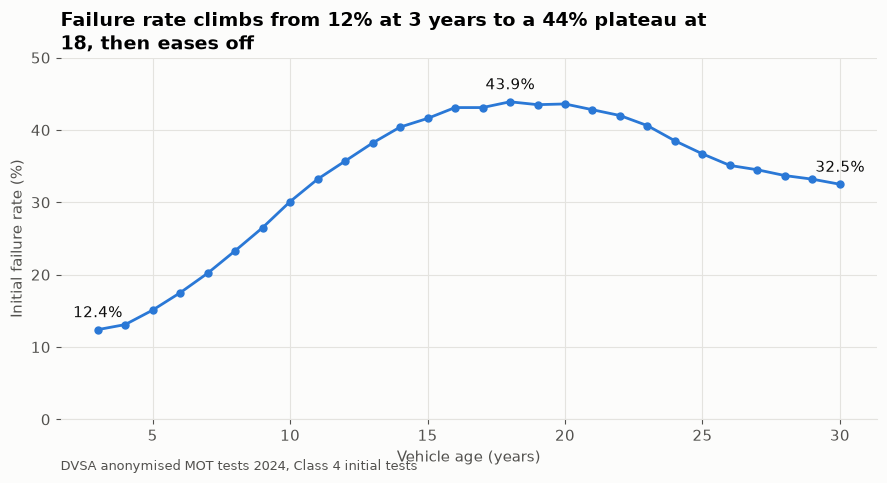

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(by_age["age"], by_age["fail_pct"], color=SLOT[0], marker="o", markersize=5)
peak = by_age.loc[by_age["fail_pct"].idxmax()]
for _, r in by_age[by_age["age"].isin([3, int(peak["age"]), 30])].iterrows():
    ax.annotate(f"{r['fail_pct']:.1f}%", (r["age"], r["fail_pct"]), textcoords="offset points",
                xytext=(0, 9), ha="center", color=INK)
ax.set_title("Failure rate climbs from 12% at 3 years to a 44% plateau at 18, then eases off")
ax.set_xlabel("Vehicle age (years)"); ax.set_ylabel("Initial failure rate (%)")
ax.set_ylim(0, 50)
finish(fig, ax, "01_fail_rate_by_age")

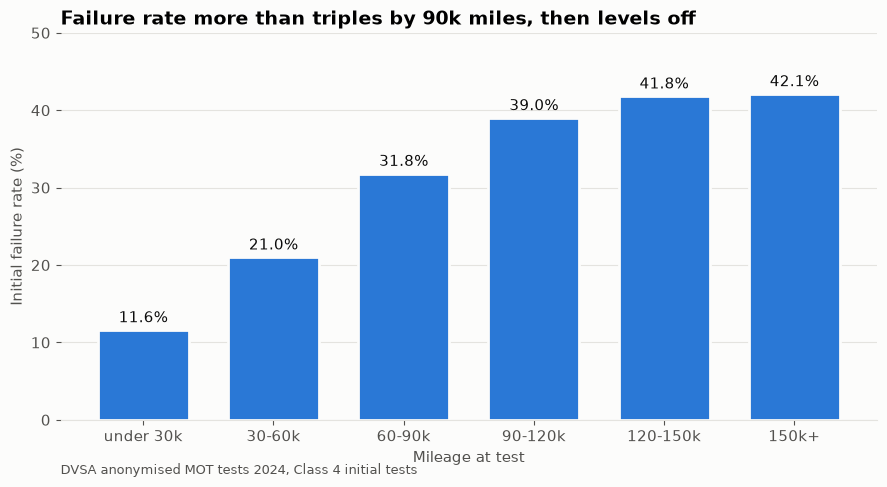

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = by_mileage["mileage_band"].str[3:]
bars = ax.bar(labels, by_mileage["fail_pct"], color=SLOT[0], width=0.7, edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, fmt="%.1f%%", padding=3, color=INK)
ax.set_title("Failure rate more than triples by 90k miles, then levels off")
ax.set_xlabel("Mileage at test"); ax.set_ylabel("Initial failure rate (%)")
ax.set_ylim(0, 50); ax.grid(axis="x", visible=False)
finish(fig, ax, "02_fail_rate_by_mileage")

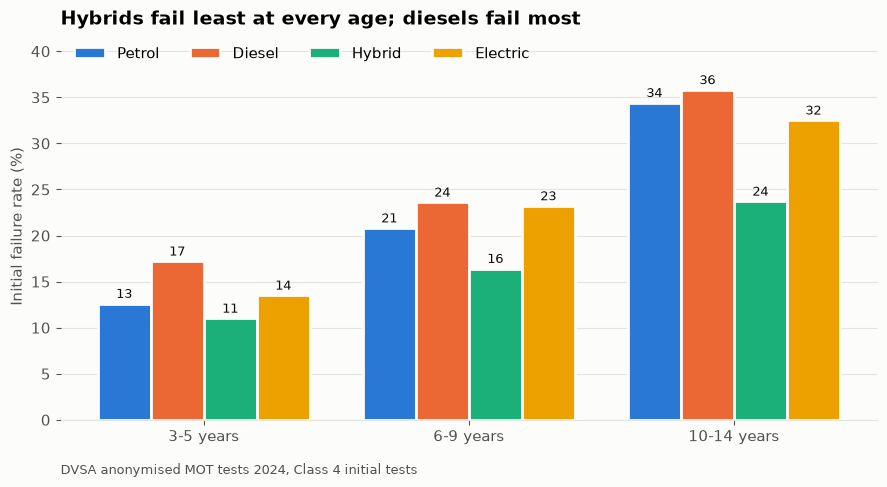

In [18]:
fuels = ["Petrol", "Diesel", "Hybrid", "Electric"]  # colour follows the fuel type in every chart
bands = ["3-5", "6-9", "10-14"]
w = 0.2
fig, ax = plt.subplots(figsize=(9, 5))
for i, fuel in enumerate(fuels):
    d = by_fuel[by_fuel["fuel_type_desc"] == fuel].set_index("age_band").loc[bands]
    bars = ax.bar([b + (i - 1.5) * w for b in range(len(bands))], d["fail_pct"], width=w,
                  color=SLOT[i], edgecolor=SURFACE, linewidth=2, label=fuel)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=9, color=INK)
ax.set_xticks(range(len(bands)), [f"{b} years" for b in bands])
ax.set_title("Hybrids fail least at every age; diesels fail most")
ax.set_ylabel("Initial failure rate (%)"); ax.set_ylim(0, 42); ax.grid(axis="x", visible=False)
ax.legend(ncols=4, loc="upper left")
finish(fig, ax, "03_fail_rate_by_fuel_and_age")

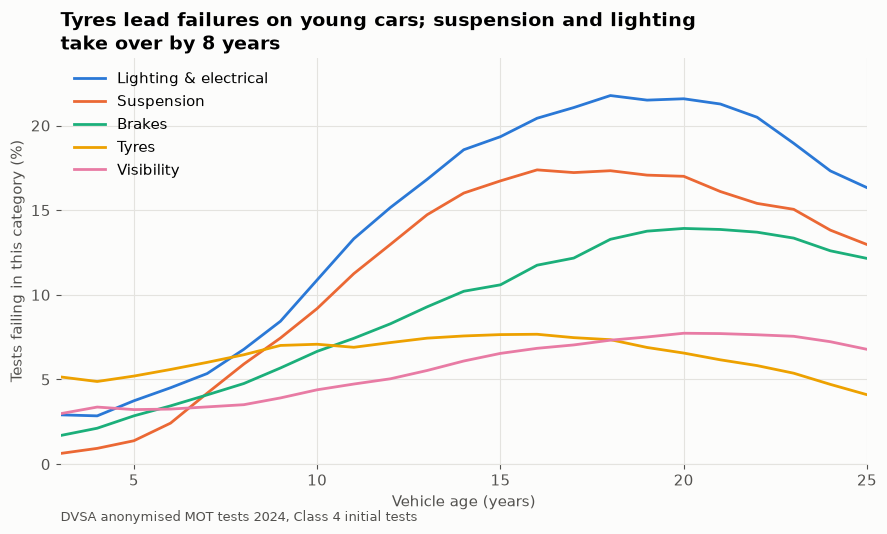

In [19]:
short = {"Lamps, reflectors and electrical equipment": "Lighting & electrical"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, cat in enumerate(top5):
    s = cat_age_wide[cat]
    ax.plot(s.index, s.values, color=SLOT[i], label=short.get(cat, cat))
ax.set_title("Tyres lead failures on young cars; suspension and lighting take over by 8 years")
ax.set_xlabel("Vehicle age (years)"); ax.set_ylabel("Tests failing in this category (%)")
ax.set_xlim(3, 25); ax.set_ylim(0, 24); ax.set_xticks(range(5, 26, 5))
ax.legend(loc="upper left")
finish(fig, ax, "04_defect_category_by_age")

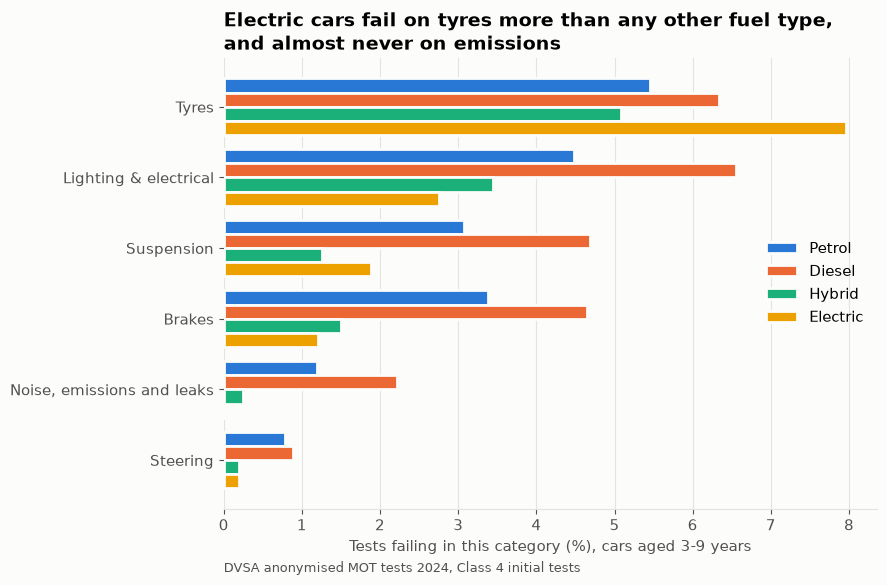

In [20]:
cats = ["Tyres", "Lamps, reflectors and electrical equipment", "Suspension", "Brakes",
        "Noise, emissions and leaks", "Steering"]
h = 0.2
fig, ax = plt.subplots(figsize=(9, 6))
for i, fuel in enumerate(fuels):
    vals = fuel_cat_wide.loc[cats, fuel]
    ax.barh([c + (i - 1.5) * h for c in range(len(cats))], vals, height=h, color=SLOT[i],
            edgecolor=SURFACE, linewidth=2, label=fuel)
ax.set_yticks(range(len(cats)), [short.get(c, c) for c in cats])
ax.invert_yaxis()
ax.set_title("Electric cars fail on tyres more than any other fuel type, and almost never on emissions")
ax.set_xlabel("Tests failing in this category (%), cars aged 3-9 years")
ax.grid(axis="y", visible=False)
ax.legend(loc="center right")
finish(fig, ax, "05_defect_category_by_fuel")

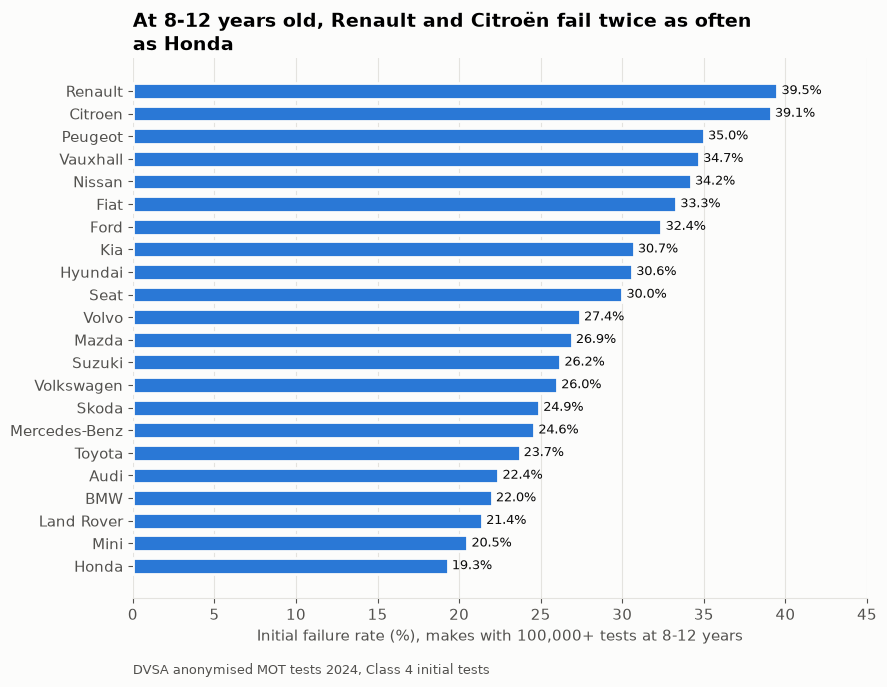

In [21]:
d = by_make.sort_values("fail_pct")
fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(d["make"].str.title().replace({"Bmw": "BMW"}), d["fail_pct"], color=SLOT[0], height=0.7, edgecolor=SURFACE, linewidth=2)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9, color=INK)
ax.set_title("At 8-12 years old, Renault and Citroën fail twice as often as Honda")
ax.set_xlabel("Initial failure rate (%), makes with 100,000+ tests at 8-12 years")
ax.set_xlim(0, 45); ax.grid(axis="y", visible=False)
finish(fig, ax, "06_fail_rate_by_make")

In [22]:
#con.close()